# ДЗ‑2. Как агент находит источник ответа

Сравним две нарезки одного снимка Википедии. На каждый вопрос поиск получает только текст вопроса. Эталонную цитату и URL используем после поиска, чтобы проверить, в какой позиции появился правильный фрагмент.

Ячейки читают сохранённый результат эксперимента и сверяют его с исходными файлами. Для полного пересчёта подготовьте окружение по `hw2/README.md` и выполните команды из корня репозитория.

```bash
docker compose -f hw2/docker-compose.yml up -d --wait
hw2/.venv/bin/python -m hw2.chunk_corpus
hw2/.venv/bin/python -m hw2.run_retrieval
```

In [1]:
import hashlib
import json
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

cwd = Path.cwd()
hw2 = cwd / "hw2" if (cwd / "hw2" / "prepare_corpus.py").is_file() else cwd
sys.path.insert(0, str(hw2.parent))
from hw2.prepare_corpus import normalize_evidence


def read_rows(name):
    return [json.loads(line) for line in (hw2 / "data" / name).read_text(encoding="utf-8").splitlines() if line]


report = json.loads((hw2 / "results" / "retrieval.json").read_text(encoding="utf-8"))
articles = read_rows("corpus.jsonl")
questions = read_rows("questions.jsonl")
negative = read_rows("unanswerable.jsonl")
for name in ("corpus.jsonl", "questions.jsonl"):
    digest = hashlib.sha256((hw2 / "data" / name).read_bytes()).hexdigest()
    assert digest == report["input_sha256"][name], f"Изменился исходный файл {name}, требуется пересчёт."

source = {a["url"]: " " + normalize_evidence(a["text"]) + " " for a in articles}
covered = sum(" " + normalize_evidence(q["evidence"]) + " " in source[q["url"]] for q in questions)
assert covered == len(questions) == report["query_count"]
print(f"Статей — {len(articles)}. Полная цитата на странице источника — {covered} из {len(questions)}.")
print(f"Отдельная выборка для будущей проверки отказов — {len(negative)} вопросов.")
print(f"{report['backend']} · {report['index']} · {report['metric']} · {report['model']} · {report['dimension']} координат")

Статей — 30. Полная цитата на странице источника — 104 из 104.
Отдельная выборка для будущей проверки отказов — 10 вопросов.
Milvus Standalone · FLAT · COSINE · Xenova/all-MiniLM-L6-v2 · 384 координат


## Векторный поиск

Успех при `k = 5` означает, что среди первых пяти результатов есть фрагмент с целой эталонной цитатой из нужной статьи. Доля успехов среди всех вопросов с ответом — `recall@5`. Если граница нарезки разделила цитату, вопрос остаётся в знаменателе.

Символьный вариант использует окна по 600 символов с перекрытием 100. Структурный сохраняет строку хронологии или абзац, чтобы сведения об одном событии оказались рядом.

По символам: фрагментов — 1901, целая цитата есть у 94 из 104 вопросов.
По структуре: фрагментов — 8223, целая цитата есть у 104 из 104 вопросов.


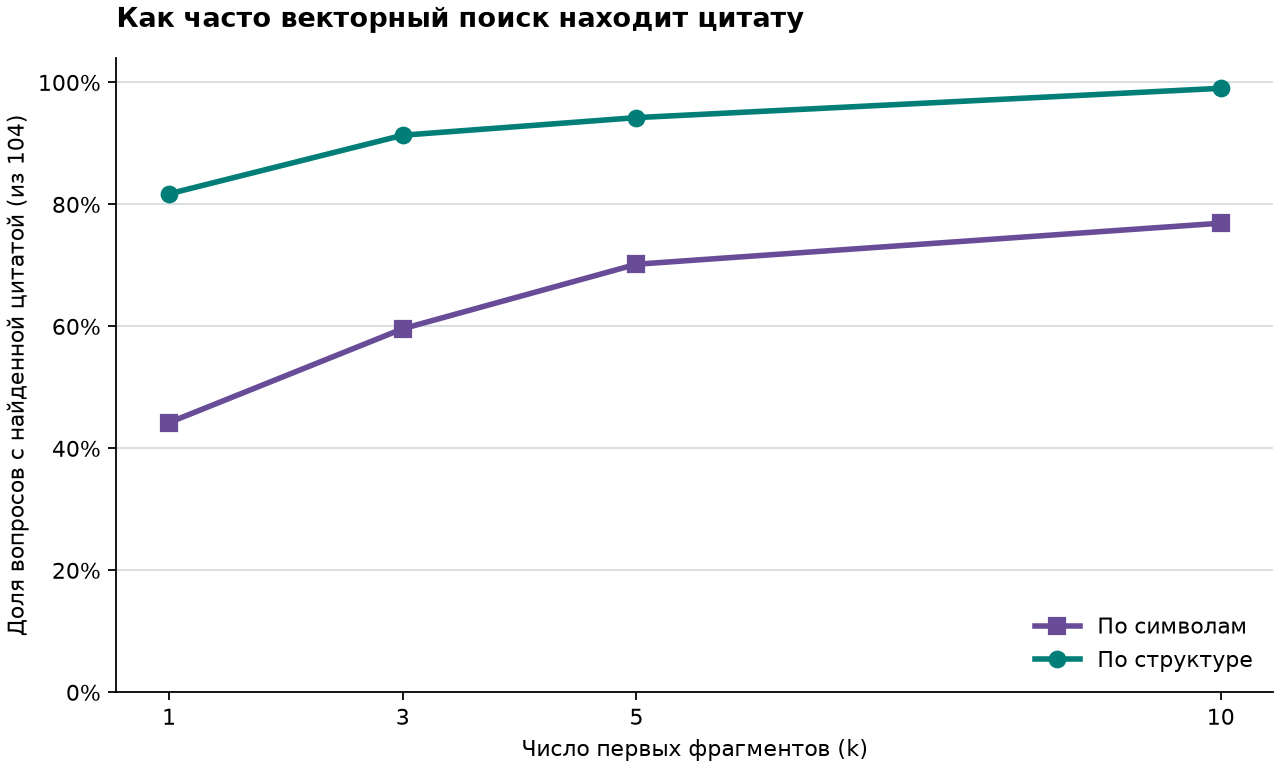

In [2]:
results = report["methods"]
for scheme, label in (("char", "По символам"), ("structure", "По структуре")):
    part = results[scheme]
    print(f"{label}: фрагментов — {part['chunk_count']}, целая цитата есть у {part['gold_coverage']} из {len(questions)} вопросов.")
display(Image(filename=str(hw2 / "results" / "recall_at_k.png"), width=720))

## Что добавляет гибридный поиск

BM25 ищет по словам. Milvus сравнивает векторы текстов. RRF объединяет две выдачи по местам фрагментов. Каждой позиции `r`, начиная с первой, соответствует вес `1 / (60 + r)`. Если фрагмент встретился в обеих выдачах, веса складываются.

В таблице каждая ячейка показывает число найденных цитат из всей выборки и соответствующую долю.

In [3]:
ks = (1, 3, 5, 10)
methods = (("vector", "Векторы"), ("bm25", "BM25"), ("rrf", "RRF"))
table = ["| Нарезка | Поиск | " + " | ".join(f"recall@{k}" for k in ks) + " |",
         "|---|---|" + "---:|" * len(ks)]
for scheme, label in (("char", "По символам"), ("structure", "По структуре")):
    for name, method_label in methods:
        metric = results[scheme]["metrics"][name]
        values = [f"{metric['hits'][str(k)]}/{len(questions)} ({metric['recall'][str(k)]:.1%})" for k in ks]
        table.append("| " + " | ".join([label, method_label, *values]) + " |")
display(Markdown("\n".join(table)))
print(f"Глубина каждой выдачи перед объединением — {results['structure']['depth']} фрагментов.")

| Нарезка | Поиск | recall@1 | recall@3 | recall@5 | recall@10 |
|---|---|---:|---:|---:|---:|
| По символам | Векторы | 46/104 (44.2%) | 62/104 (59.6%) | 73/104 (70.2%) | 80/104 (76.9%) |
| По символам | BM25 | 79/104 (76.0%) | 92/104 (88.5%) | 93/104 (89.4%) | 93/104 (89.4%) |
| По символам | RRF | 64/104 (61.5%) | 84/104 (80.8%) | 88/104 (84.6%) | 91/104 (87.5%) |
| По структуре | Векторы | 85/104 (81.7%) | 95/104 (91.3%) | 98/104 (94.2%) | 103/104 (99.0%) |
| По структуре | BM25 | 95/104 (91.3%) | 101/104 (97.1%) | 103/104 (99.0%) | 103/104 (99.0%) |
| По структуре | RRF | 95/104 (91.3%) | 103/104 (99.0%) | 103/104 (99.0%) | 103/104 (99.0%) |

Глубина каждой выдачи перед объединением — 100 фрагментов.


**Для генерации выбираем структурную нарезку, RRF и три фрагмента.** На этом снимке у RRF в первых трёх результатах нашлась цитата для 103 из 104 вопросов. Переход к пяти или десяти сохранил те же 103 попадания. BM25 достигает этого результата при пяти фрагментах. Размер контекста и стоимость генерации измерим отдельно на этапе ответов.

## Где позиции изменились

Посмотрим на два вопроса, для которых объединение рангов дало разный эффект. Прочерк означает, что правильный фрагмент отсутствовал в выдаче метода на сохранённой глубине.

In [4]:
observations = {row["id"]: row for row in results["structure"]["questions"]}
by_id = {q["id"]: q for q in questions}
for question_id in ("fresh-39", "fresh-88"):
    if question_id not in observations:
        continue
    q = by_id[question_id]
    print(f"{question_id} · {q['page']}")
    print(q["question"])
    print("Эталонная цитата:", q["evidence"])
    for name, label in methods:
        position = observations[question_id]["results"][name]["rank"]
        print(f"{label}: {position if position is not None else '—'}")
    print()

fresh-39 · 2026 in Spain
What was the location of the train collision in Spain on January 20, 2026?
Эталонная цитата: 20 January – A Rodalies de Catalunya train collides with a retaining wall that had fallen on the track in Gelida, killing the driver and injuring 37 passengers.
Векторы: 4
BM25: 4
RRF: 2

fresh-88 · 2026 in Japan
What was the location of the boat capsizing in Japan in March 2026?
Эталонная цитата: March 16 – Two boats carrying high school students on a field trip capsize off Henoko, Okinawa Prefecture, killing two people.
Векторы: 3
BM25: —
RRF: 30



## Поиск внутри статьи

Если пользователь спрашивает о канадской хронологии, инструмент может ограничить поиск статьёй `2026 in Canada`. В этом примере предикат по полю `page` передан в запрос Milvus. Ниже выводятся фрагменты из сохранённого ответа на этот запрос.

In [5]:
demo = report["filter_demo"]
assert demo["hits"] and all(hit["page"] == demo["page_filter"] for hit in demo["hits"])
print(demo["query"])
print(f"Фильтр по статье: {demo['page_filter']}")
for i, hit in enumerate(demo["hits"], start=1):
    section = hit["section"] or "Вступление"
    print(f"\n{i}. {hit['page']} · {section}\n{hit['text']}")

In the Canada timeline, what did Statistics Canada announce about jobs?
Фильтр по статье: 2026 in Canada

1. 2026 in Canada · Events / January
January 13 – Statistics Canada announces 850 job cuts, with over 100 to happen in the following days.

2. 2026 in Canada · Events / May
May 12 – The 2026 Canadian census takes place.

3. 2026 in Canada · Вступление
The following is a list of events of the year 2026 in Canada, as well as events that are scheduled or predicted to take place during the year.
